# Salary vs. years of experience: extended analysis

**PORTFOLIO IMPROVEMENT.** Added in 2026, after the Year Up capstone. The original analysis
(`../reconstruction/salary_regression_original.ipynb`) fit one straight line and reported R².
This notebook asks the follow-up questions a reviewer would ask:

1. How sure are we about the line, and about any one person's salary? (confidence and prediction intervals)
2. Does a straight line actually fit, or is it hiding a curve? (residual plot, Q-Q plot)
3. How well does it predict someone it has never seen? (leave-one-out cross-validation vs a naive baseline)
4. Where does it stop being trustworthy? (extrapolation)

The model code lives in `salary_model.py` and is checked by `tests/test_salary_model.py`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import salary_model as model

# Chart styling shared by every figure: one blue for data, one orange for a fitted line
# or reference mark, quiet grid, no top/right spines.
C = {"blue": "#2a78d6", "orange": "#eb6834", "text": "#0b0b0b", "muted": "#52514e",
     "grid": "#e6e5e1", "surface": "#fcfcfb"}
plt.rcParams.update({
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"], "savefig.facecolor": C["surface"],
    "axes.edgecolor": C["grid"], "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "text.color": C["text"], "axes.labelcolor": C["muted"], "axes.titlecolor": C["text"],
    "xtick.color": C["muted"], "ytick.color": C["muted"], "font.size": 11, "figure.dpi": 110,
})
money = lambda v, _: f"${v/1000:,.0f}k"

In [2]:
df = model.load_data()
result = model.fit_ols(df)
summary = model.summarize(result)
pd.DataFrame({"value": summary}).round(4)

,value
n,30.0000
intercept,25792.2002
slope,9449.9623
slope_std_err,378.7546
slope_p_value,0.0000
r_squared,0.9570
adj_r_squared,0.9554
residual_std,5788.3151


## 1. The line, with honest error bars

Two bands around the fitted line, both at 95%:

- **Confidence interval** (darker): where the *average* salary for that level of experience probably sits.
  Narrow, because averaging 30 people pins it down.
- **Prediction interval** (lighter): where *one person's* salary probably sits. Much wider, because
  individuals vary around the average. This is the band that matters if you use the model to predict
  your own salary.

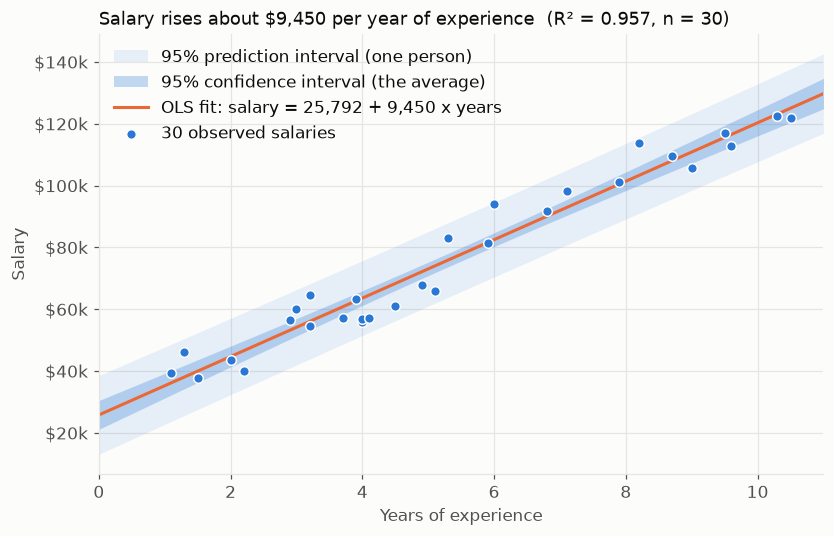

In [3]:
grid = np.linspace(0, 11, 120)
bands = model.prediction_intervals(result, grid)

fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.fill_between(bands.years, bands.pi_low, bands.pi_high, color=C["blue"], alpha=0.10, linewidth=0,
                label="95% prediction interval (one person)")
ax.fill_between(bands.years, bands.ci_low, bands.ci_high, color=C["blue"], alpha=0.28, linewidth=0,
                label="95% confidence interval (the average)")
ax.plot(bands.years, bands.predicted, color=C["orange"], linewidth=2,
        label=f"OLS fit: salary = {summary['intercept']:,.0f} + {summary['slope']:,.0f} x years")
ax.scatter(df.YearsExperience, df.Salary, s=40, color=C["blue"], edgecolor=C["surface"], linewidth=1,
           zorder=3, label="30 observed salaries")
ax.set_xlabel("Years of experience")
ax.set_ylabel("Salary")
ax.yaxis.set_major_formatter(money)
ax.set_xlim(0, 11)
ax.set_title(f"Salary rises about ${summary['slope']:,.0f} per year of experience  (R² = {summary['r_squared']:.3f}, n = 30)",
             loc="left", fontsize=12)
ax.legend(frameon=False, loc="upper left")
fig.savefig("../docs/salary_fit_with_intervals.png", dpi=130, bbox_inches="tight")
plt.show()

## 2. Does a straight line fit?

R² alone cannot tell you. Two standard checks:

- **Residuals vs fitted.** Residual = actual minus predicted. If a straight line is the right shape, the
  dots should scatter evenly around zero with no curve and no funnel.
- **Q-Q plot.** Compares the residuals to a normal distribution. Dots hugging the line mean the
  intervals above can be trusted; a strong S-shape or tails peeling away would mean they cannot.

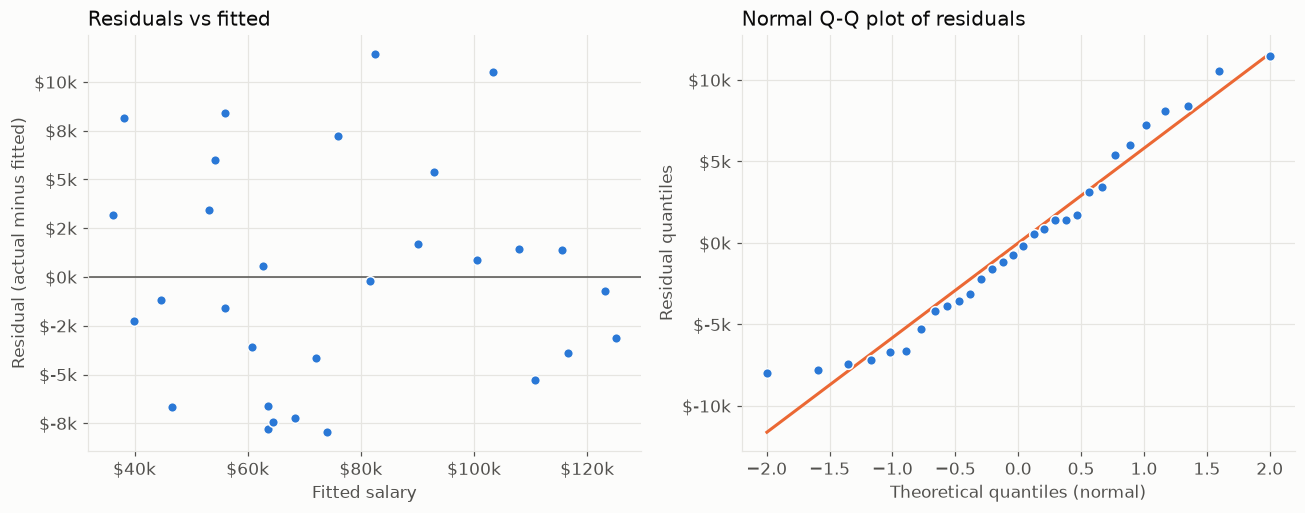

Residual standard deviation: $5,788
Shapiro-Wilk normality test: W = 0.952, p = 0.195  (no evidence against normality)


In [4]:
resid = result.resid
fitted = result.fittedvalues

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

ax1.axhline(0, color=C["muted"], linewidth=1)
ax1.scatter(fitted, resid, s=40, color=C["blue"], edgecolor=C["surface"], linewidth=1, zorder=3)
ax1.set_xlabel("Fitted salary")
ax1.set_ylabel("Residual (actual minus fitted)")
ax1.xaxis.set_major_formatter(money)
ax1.yaxis.set_major_formatter(money)
ax1.set_title("Residuals vs fitted", loc="left")

(osm, osr), (slope_qq, intercept_qq, _) = stats.probplot(resid, dist="norm")
ax2.plot(osm, slope_qq * osm + intercept_qq, color=C["orange"], linewidth=2)
ax2.scatter(osm, osr, s=40, color=C["blue"], edgecolor=C["surface"], linewidth=1, zorder=3)
ax2.set_xlabel("Theoretical quantiles (normal)")
ax2.set_ylabel("Residual quantiles")
ax2.yaxis.set_major_formatter(money)
ax2.set_title("Normal Q-Q plot of residuals", loc="left")

fig.tight_layout()
fig.savefig("../docs/salary_residuals.png", dpi=130, bbox_inches="tight")
plt.show()

shapiro = stats.shapiro(resid)
print(f"Residual standard deviation: ${summary['residual_std']:,.0f}")
print(f"Shapiro-Wilk normality test: W = {shapiro.statistic:.3f}, p = {shapiro.pvalue:.3f}  "
      f"({'no evidence against normality' if shapiro.pvalue > 0.05 else 'residuals look non-normal'})")

## 3. How well does it predict someone new?

R² is measured on the same 30 people the line was fit to, so it flatters the model. Leave-one-out
cross-validation is fairer: hide one person, fit the line on the other 29, predict the hidden one,
repeat 30 times. The root-mean-square error (RMSE) of those 30 misses is what you would expect on a
new person from the same population.

The baseline to beat is the laziest possible model: always guess the average salary.

In [5]:
cv = model.leave_one_out_rmse(df)
mean_salary = df.Salary.mean()
pd.DataFrame({
    "approach": ["Always guess the average salary", "Straight line on years of experience"],
    "leave-one-out RMSE": [cv["baseline_rmse"], cv["model_rmse"]],
    "as % of the average salary": [100 * cv["baseline_rmse"] / mean_salary, 100 * cv["model_rmse"] / mean_salary],
}).round(1)

,approach,leave-one-out RMSE,as % of the average salary
0,Always guess the average salary,27883.1,36.7
1,Straight line on years of experience,5924.5,7.8


## 4. Where it stops being trustworthy

The data covers 1.1 to 10.5 years of experience. Inside that range the line is backed by
observations. Outside it, the line keeps going but the data does not. The 0-year row says a brand
new hire earns the intercept; the 25-year row says a veteran earns a quarter million. Neither is a
finding, both are the straight line continuing past the evidence.

In [6]:
checks = model.prediction_intervals(result, [0, 2, 5, 10.5, 15, 25])
low, high = df.YearsExperience.min(), df.YearsExperience.max()
checks["inside the data"] = checks.years.between(low, high)
checks.round({"predicted": 0, "ci_low": 0, "ci_high": 0, "pi_low": 0, "pi_high": 0})

,years,predicted,ci_low,ci_high,pi_low,pi_high,inside the data
0,0.0,25792.0,21136.0,30448.0,13054.0,38530.0,False
1,2.0,44692.0,41331.0,48053.0,32368.0,57016.0,True
2,5.0,73042.0,70864.0,75220.0,60987.0,85097.0,True
3,10.5,125017.0,120447.0,129586.0,112310.0,137724.0,True
4,15.0,167542.0,159721.0,175363.0,153338.0,181746.0,False
5,25.0,262041.0,246615.0,277468.0,242585.0,281498.0,False


## What this model cannot tell you

- **Thirty people.** One small, widely shared teaching dataset. The tidy R² is partly a property of
  the dataset, not of the labor market.
- **One input.** Experience alone. Role, industry, location, education and negotiation all move salary
  and none of them are here. Add any of them and the slope on experience would change.
- **A straight line forever.** Real pay growth tends to flatten later in a career. The data stops at
  10.5 years, so the model has never seen that happen.
- **Correlation, not cause.** Staying in a job another year does not hand you $9,450. People with more
  experience also tend to have more seniority, bigger networks and more negotiating leverage.
- **Point estimates are too confident.** Quote the prediction interval, not the single number. At 5
  years that is roughly $61k to $85k, not "$73,042".